In [1]:
import os
import random
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.utils import save_image

# Safe CPU settings for a computer with 8 GB RAM
device = torch.device("cpu")
torch.set_num_threads(2)

random.seed(42)
torch.manual_seed(42)

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Safe CPU settings enabled.")

Device: cpu
PyTorch: 2.13.0+cpu
Safe CPU settings enabled.


In [2]:
dataset_path = Path(
    r"C:\Gen ai Project\GANs\Dataset\img_align_celeba\img_align_celeba"
)

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {dataset_path}\n"
        "Check the folder path before continuing."
    )

print("Dataset folder found:", dataset_path)

Dataset folder found: C:\Gen ai Project\GANs\Dataset\img_align_celeba\img_align_celeba


In [3]:
class CelebADataset(Dataset):

    def __init__(self, root_dir, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform

        self.image_files = sorted([
            p for p in self.root_dir.iterdir()
            if p.is_file()
            and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ])

        if not self.image_files:
            raise RuntimeError(
                f"No images found in {self.root_dir}"
            )

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):
        image_path = self.image_files[index]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

In [4]:
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

dataset = CelebADataset(
    root_dir=dataset_path,
    transform=transform
)

MAX_IMAGES = 500
num_images = min(MAX_IMAGES, len(dataset))

# Select a reproducible subset
rng = random.Random(42)
indices = list(range(len(dataset)))
rng.shuffle(indices)
indices = indices[:num_images]

small_dataset = Subset(dataset, indices)

print("Total images available:", len(dataset))
print("Images selected for training:", len(small_dataset))

Total images available: 202599
Images selected for training: 500


In [5]:
BATCH_SIZE = 4

dataloader = DataLoader(
    small_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)

print("Batch size:", BATCH_SIZE)
print("Batches per epoch:", len(dataloader))

# Check one batch before training
sample_batch = next(iter(dataloader))
print("Batch shape:", sample_batch.shape)

del sample_batch

Batch size: 4
Batches per epoch: 125
Batch shape: torch.Size([4, 3, 32, 32])


In [6]:
LATENT_DIM = 64

class Generator(nn.Module):

    def __init__(self):
        super().__init__()

        self.project = nn.Sequential(
            nn.Linear(LATENT_DIM, 128 * 4 * 4),
            nn.ReLU(inplace=True)
        )

        self.model = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, noise):
        x = self.project(noise)
        x = x.view(noise.size(0), 128, 4, 4)
        return self.model(x)


generator = Generator().to(device)

print(generator)

Generator(
  (project): Sequential(
    (0): Linear(in_features=64, out_features=2048, bias=True)
    (1): ReLU(inplace=True)
  )
  (model): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)


In [7]:
class Discriminator(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.output = nn.Linear(128 * 4 * 4, 1)

    def forward(self, image):
        x = self.features(image)
        x = x.flatten(start_dim=1)
        return self.output(x)


discriminator = Discriminator().to(device)

print(discriminator)

Discriminator(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
  )
  (output): Linear(in_features=2048, out_features=1, bias=True)
)


In [8]:
criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

print("Loss function and optimizers created successfully.")

Loss function and optimizers created successfully.


In [9]:
OUTPUT_DIR = Path("gan_outputs")
CHECKPOINT_DIR = Path("gan_checkpoints")

OUTPUT_DIR.mkdir(exist_ok=True)
CHECKPOINT_DIR.mkdir(exist_ok=True)

print("Output folder:", OUTPUT_DIR.resolve())
print("Checkpoint folder:", CHECKPOINT_DIR.resolve())

Output folder: C:\Gen ai Project\GANs\gan_outputs
Checkpoint folder: C:\Gen ai Project\GANs\gan_checkpoints


In [10]:
def save_generated_images(epoch):
    generator.eval()

    with torch.no_grad():
        noise = torch.randn(16, LATENT_DIM, device=device)
        fake_images = generator(noise)

        save_image(
            fake_images,
            OUTPUT_DIR / f"generated_epoch_{epoch}.png",
            nrow=4,
            normalize=True,
            value_range=(-1, 1)
        )

    generator.train()


def train_gan(epochs=1):
    generator.train()
    discriminator.train()

    for epoch in range(epochs):
        total_g_loss = 0.0
        total_d_loss = 0.0

        for batch_index, real_images in enumerate(dataloader):
            real_images = real_images.to(device)
            batch_size = real_images.size(0)

            real_labels = torch.ones(batch_size, 1, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)

            # ---------------------------
            # 1. Train Discriminator
            # ---------------------------
            optimizer_D.zero_grad(set_to_none=True)

            real_output = discriminator(real_images)
            real_loss = criterion(real_output, real_labels)

            noise = torch.randn(batch_size, LATENT_DIM, device=device)

            with torch.no_grad():
                fake_images = generator(noise)

            fake_output = discriminator(fake_images)
            fake_loss = criterion(fake_output, fake_labels)

            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()
            optimizer_D.step()

            # ---------------------------
            # 2. Train Generator
            # ---------------------------
            optimizer_G.zero_grad(set_to_none=True)

            noise = torch.randn(batch_size, LATENT_DIM, device=device)
            generated_images = generator(noise)

            # Generator wants the Discriminator to classify
            # generated images as real.
            generator_output = discriminator(generated_images)
            g_loss = criterion(generator_output, real_labels)

            g_loss.backward()
            optimizer_G.step()

            total_d_loss += d_loss.item()
            total_g_loss += g_loss.item()

            if batch_index % 10 == 0:
                print(
                    f"Epoch {epoch + 1}/{epochs} | "
                    f"Batch {batch_index + 1}/{len(dataloader)} | "
                    f"D Loss: {d_loss.item():.4f} | "
                    f"G Loss: {g_loss.item():.4f}"
                )

            # Release references to temporary tensors.
            del (
                real_images,
                real_output,
                fake_output,
                fake_images,
                generated_images,
                generator_output,
                noise,
                d_loss,
                g_loss
            )

        avg_d_loss = total_d_loss / max(len(dataloader), 1)
        avg_g_loss = total_g_loss / max(len(dataloader), 1)

        print(f"\nEpoch {epoch + 1} completed")
        print(f"Average Discriminator Loss: {avg_d_loss:.4f}")
        print(f"Average Generator Loss: {avg_g_loss:.4f}")

        # Save generated samples.
        save_generated_images(epoch + 1)

        # Save training progress.
        torch.save({
            "epoch": epoch + 1,
            "generator": generator.state_dict(),
            "discriminator": discriminator.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
            "optimizer_D": optimizer_D.state_dict(),
            "latent_dim": LATENT_DIM
        }, CHECKPOINT_DIR / "latest_checkpoint.pth")

        print("Checkpoint saved successfully.\n")

    print("Training completed.")


# Start with only one epoch.
train_gan(epochs=1)

Epoch 1/1 | Batch 1/125 | D Loss: 0.8163 | G Loss: 0.7673
Epoch 1/1 | Batch 11/125 | D Loss: 0.2727 | G Loss: 1.4881
Epoch 1/1 | Batch 21/125 | D Loss: 0.2706 | G Loss: 1.6387
Epoch 1/1 | Batch 31/125 | D Loss: 0.1749 | G Loss: 2.2571
Epoch 1/1 | Batch 41/125 | D Loss: 0.1833 | G Loss: 2.3187
Epoch 1/1 | Batch 51/125 | D Loss: 0.1177 | G Loss: 2.3723
Epoch 1/1 | Batch 61/125 | D Loss: 0.0796 | G Loss: 2.7313
Epoch 1/1 | Batch 71/125 | D Loss: 0.1408 | G Loss: 2.3750
Epoch 1/1 | Batch 81/125 | D Loss: 0.0929 | G Loss: 3.1726
Epoch 1/1 | Batch 91/125 | D Loss: 0.0973 | G Loss: 3.1440
Epoch 1/1 | Batch 101/125 | D Loss: 0.0655 | G Loss: 3.0236
Epoch 1/1 | Batch 111/125 | D Loss: 0.0546 | G Loss: 3.3620
Epoch 1/1 | Batch 121/125 | D Loss: 0.3605 | G Loss: 2.8979

Epoch 1 completed
Average Discriminator Loss: 0.1819
Average Generator Loss: 2.5331
Checkpoint saved successfully.

Training completed.


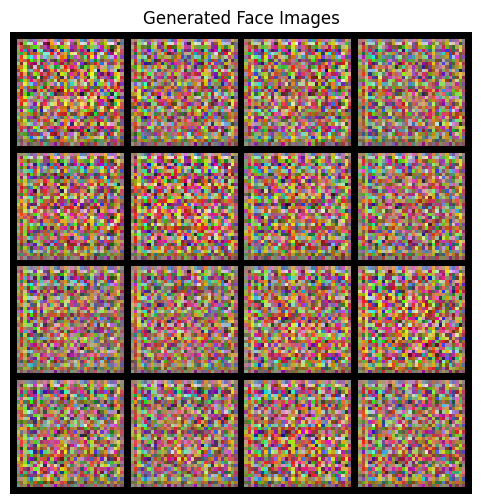

In [11]:
import matplotlib.pyplot as plt

image_path = OUTPUT_DIR / "generated_epoch_1.png"

if image_path.exists():
    with Image.open(image_path) as img:
        plt.figure(figsize=(6, 6))
        plt.imshow(img.copy())
        plt.axis("off")
        plt.title("Generated Face Images")
        plt.show()
else:
    print("Generated image file not found.")

In [12]:
generator.eval()

with torch.no_grad():
    noise = torch.randn(4, LATENT_DIM, device=device)
    new_images = generator(noise)

save_image(
    new_images,
    OUTPUT_DIR / "new_generated_images.png",
    nrow=2,
    normalize=True,
    value_range=(-1, 1)
)

print("New images saved to:", OUTPUT_DIR / "new_generated_images.png")

New images saved to: gan_outputs\new_generated_images.png
